**Seed42** uses baseline order and fixed seed 42; Baseline remains the comparison reference.
Repeated outputs with this fixed seed measure repeatability, rather than independent random-seed samples.
Completeness checks retain the planned 50 iterations per variant.


In [1]:
# Cell 1 — imports and file locations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path("/home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol")

FILES = {
    "Baseline": ROOT / "baseline-run" / "zeroshotFeasibilityResponses.csv",
    "Seed42": (
        ROOT / "outputs" / "baseline-seed42"
        / "zeroshotFeasibilityResponses_seed42.csv"
    ),
    "Run1_seed42": (
            ROOT / "outputs" / "run1-seed42"
            / "zeroshotFeasibilityResponses_seed42_run1.csv"
        ),
    **{
        f"Run{i}": (
            ROOT / "outputs" / f"run{i}"
            / f"zeroshotFeasibilityResponses_run{i}.csv"
        )
        for i in range(1, 4)
    },
}

CONDITIONS = list(FILES)
MODELS = ["phi4", "gemma3", "llama", "mistral"]

# Figure labels only; CSV identifiers and variant pooling remain unchanged.
MODEL_DISPLAY_NAMES = {
    "phi4": "Phi-4",
    "gemma3": "Gemma3:12B",
    "llama": "Llama-Pro",
    "mistral": "Mistral",
}
ROLES = {"generalist", "normative", "subject-matter"}
EXPECTED_PER_ROLE = 50

COLORS = {
    1: "#d73027",
    2: "#fc8d59",
    3: "#91bfdb",
    4: "#4575b4",
}

LABELS = {
    1: "Not feasible",
    2: "Somewhat feasible",
    3: "Feasible",
    4: "Very feasible",
}

In [2]:
# Cell 2 — load and validate the available results
frames = []

required_columns = {
    "base_model", "model", "iteration", "rating"
}

for condition, path in FILES.items():
    if not path.exists():
        print(f"{condition}: file not available yet.")
        continue

    try:
        frame = pd.read_csv(path)
    except pd.errors.EmptyDataError:
        print(f"{condition}: file is empty.")
        continue

    missing_columns = required_columns - set(frame.columns)
    if missing_columns:
        raise ValueError(
            f"{path}: missing columns {sorted(missing_columns)}"
        )

    if frame.empty:
        print(f"{condition}: no responses yet.")
        continue

    frame = frame.copy()
    frame["base_model"] = frame["base_model"].astype(str).str.strip()
    frame["role"] = frame["model"].astype(str).str.strip()
    frame["rating"] = pd.to_numeric(frame["rating"], errors="coerce")
    frame["iteration"] = pd.to_numeric(
        frame["iteration"], errors="coerce"
    )
    frame["condition"] = condition

    if not frame["rating"].isin([1, 2, 3, 4]).all():
        raise ValueError(
            f"{path}: found a missing rating or a rating outside 1–4."
        )

    valid_iteration = (
        frame["iteration"].notna()
        & frame["iteration"].ge(0)
        & frame["iteration"].mod(1).eq(0)
    )
    if not valid_iteration.all():
        raise ValueError(f"{path}: invalid iteration numbers.")

    if not frame["base_model"].isin(MODELS).all():
        raise ValueError(f"{path}: unexpected base-model names.")

    if not frame["role"].isin(ROLES).all():
        raise ValueError(f"{path}: unexpected expert-role names.")

    duplicate = frame.duplicated(
        ["base_model", "role", "iteration"],
        keep=False,
    )
    if duplicate.any():
        raise ValueError(
            f"{path}: duplicate model/role/iteration responses found."
        )

    frame["rating"] = frame["rating"].astype(int)
    frame["iteration"] = frame["iteration"].astype(int)
    frames.append(frame)

data = (
    pd.concat(frames, ignore_index=True)
    if frames
    else pd.DataFrame(
        columns=[
            "base_model", "role", "iteration",
            "rating", "condition"
        ]
    )
)

# Completion is checked by role, but reported at base-model level.
coverage_rows = []

for model in MODELS:
    for condition in CONDITIONS:
        subset = data[
            (data["base_model"] == model)
            & (data["condition"] == condition)
        ]

        counts = (
            subset.groupby("role").size()
            .reindex(sorted(ROLES), fill_value=0)
        )

        n = len(subset)
        complete = counts.eq(EXPECTED_PER_ROLE).all()

        coverage_rows.append({
            "base_model": model,
            "condition": condition,
            "responses": n,
            "minimum_per_variant": int(counts.min()),
            "maximum_per_variant": int(counts.max()),
            "status": (
                "Complete" if complete
                else "Missing" if n == 0
                else "Partial / check counts"
            ),
        })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

print(
    "\nPlots include partial data for preview. "
    "Use complete conditions for final interpretation."
)

,base_model,condition,responses,minimum_per_variant,maximum_per_variant,status
0,phi4,Baseline,150,50,50,Complete
1,phi4,Seed42,150,50,50,Complete
2,phi4,Run1_seed42,150,50,50,Complete
3,phi4,Run1,150,50,50,Complete
4,phi4,Run2,150,50,50,Complete
5,phi4,Run3,150,50,50,Complete
6,gemma3,Baseline,150,50,50,Complete
7,gemma3,Seed42,150,50,50,Complete
8,gemma3,Run1_seed42,150,50,50,Complete
9,gemma3,Run1,150,50,50,Complete



Plots include partial data for preview. Use complete conditions for final interpretation.


In [3]:
# Cell 3 — model-level summary table
summary_rows = []

for model in MODELS:
    for condition in CONDITIONS:
        ratings = data.loc[
            (data["base_model"] == model)
            & (data["condition"] == condition),
            "rating",
        ]

        row = {
            "base_model": model,
            "condition": condition,
            "n": len(ratings),
            "median": np.nan,
            "q1": np.nan,
            "q3": np.nan,
            "iqr": np.nan,
            "most_frequent_rating": None,
        }

        if not ratings.empty:
            q1 = ratings.quantile(0.25, interpolation="nearest")
            q3 = ratings.quantile(0.75, interpolation="nearest")

            row.update({
                "median": ratings.median(),
                "q1": q1,
                "q3": q3,
                "iqr": q3 - q1,
                # Retain all modes if there is a tie.
                "most_frequent_rating": ", ".join(
                    str(value) for value in ratings.mode()
                ),
            })

        summary_rows.append(row)

summary = pd.DataFrame(summary_rows)

baseline_medians = (
    summary[summary["condition"] == "Baseline"]
    .set_index("base_model")["median"]
)

summary["median_change_from_baseline"] = (
    summary["median"]
    - summary["base_model"].map(baseline_medians)
)

summary = summary.merge(
    coverage[
        ["base_model", "condition", "status"]
    ],
    on=["base_model", "condition"],
    validate="one_to_one",
)

display(summary.round(2))

,base_model,condition,n,median,q1,q3,iqr,most_frequent_rating,median_change_from_baseline,status
0,phi4,Baseline,150,3.0,3,3,0,3,0.0,Complete
1,phi4,Seed42,150,3.0,3,4,1,3,0.0,Complete
2,phi4,Run1_seed42,150,3.0,3,4,1,3,0.0,Complete
3,phi4,Run1,150,3.0,3,3,0,3,0.0,Complete
4,phi4,Run2,150,3.0,3,3,0,3,0.0,Complete
5,phi4,Run3,150,3.0,3,3,0,3,0.0,Complete
6,gemma3,Baseline,150,3.0,3,3,0,3,0.0,Complete
7,gemma3,Seed42,150,3.0,3,3,0,3,0.0,Complete
8,gemma3,Run1_seed42,150,3.0,3,3,0,3,0.0,Complete
9,gemma3,Run1,150,3.0,3,3,0,3,0.0,Complete


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_phi4.png
Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_phi4.eps


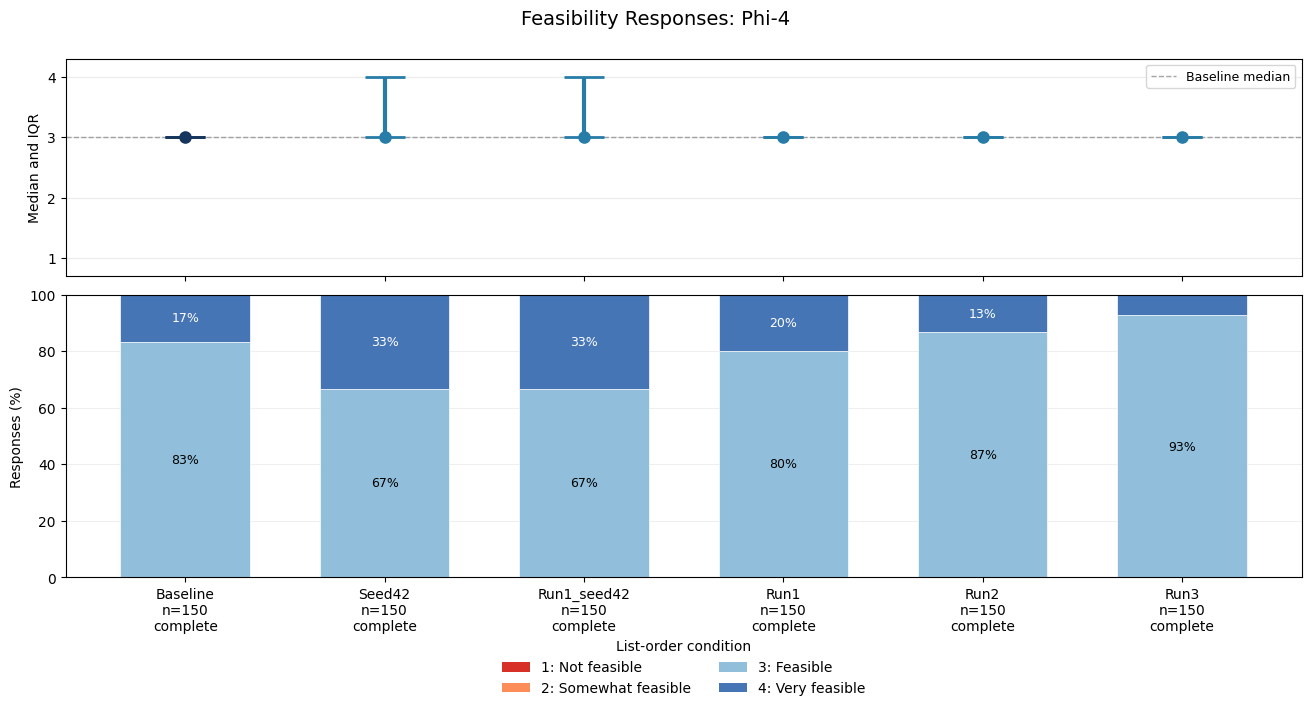

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_gemma3.png
Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_gemma3.eps


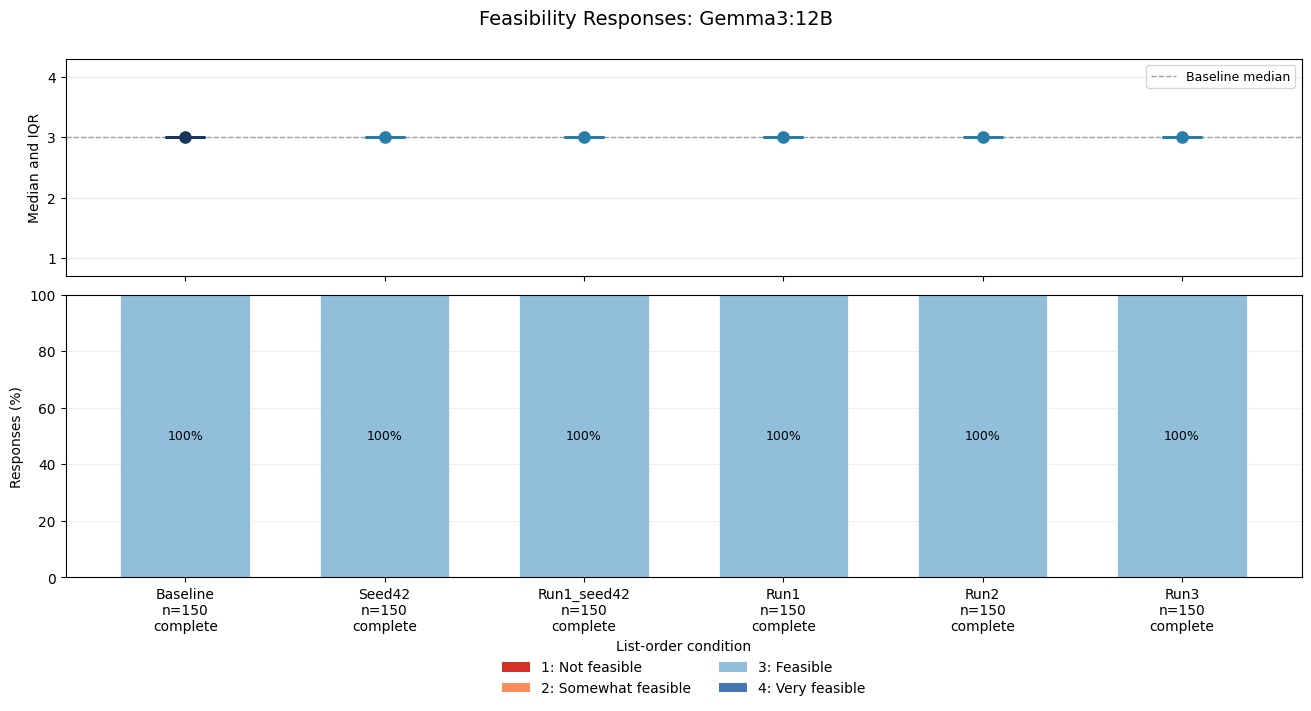

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_llama.png
Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_llama.eps


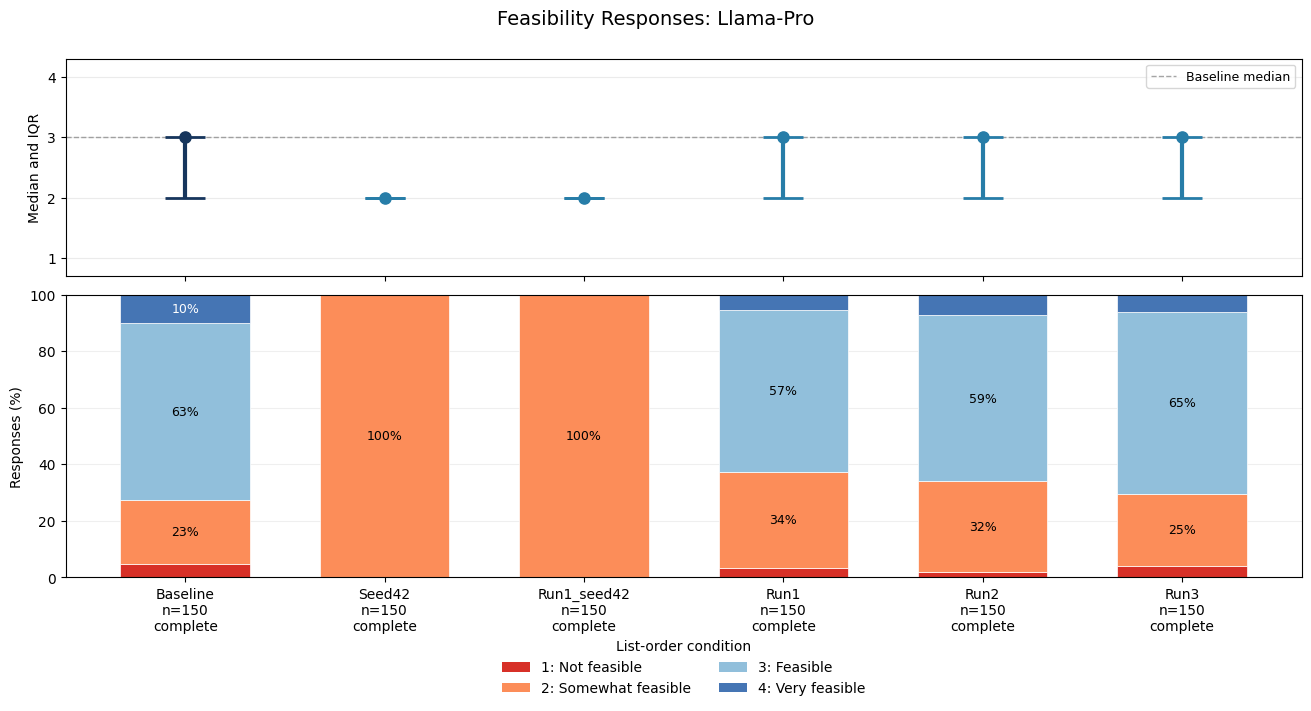

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_mistral.png
Saved: /home/ngirwa/TiiS/second-publication/variability-tests/variability-feasibility-sol/feasibility-responses_mistral.eps


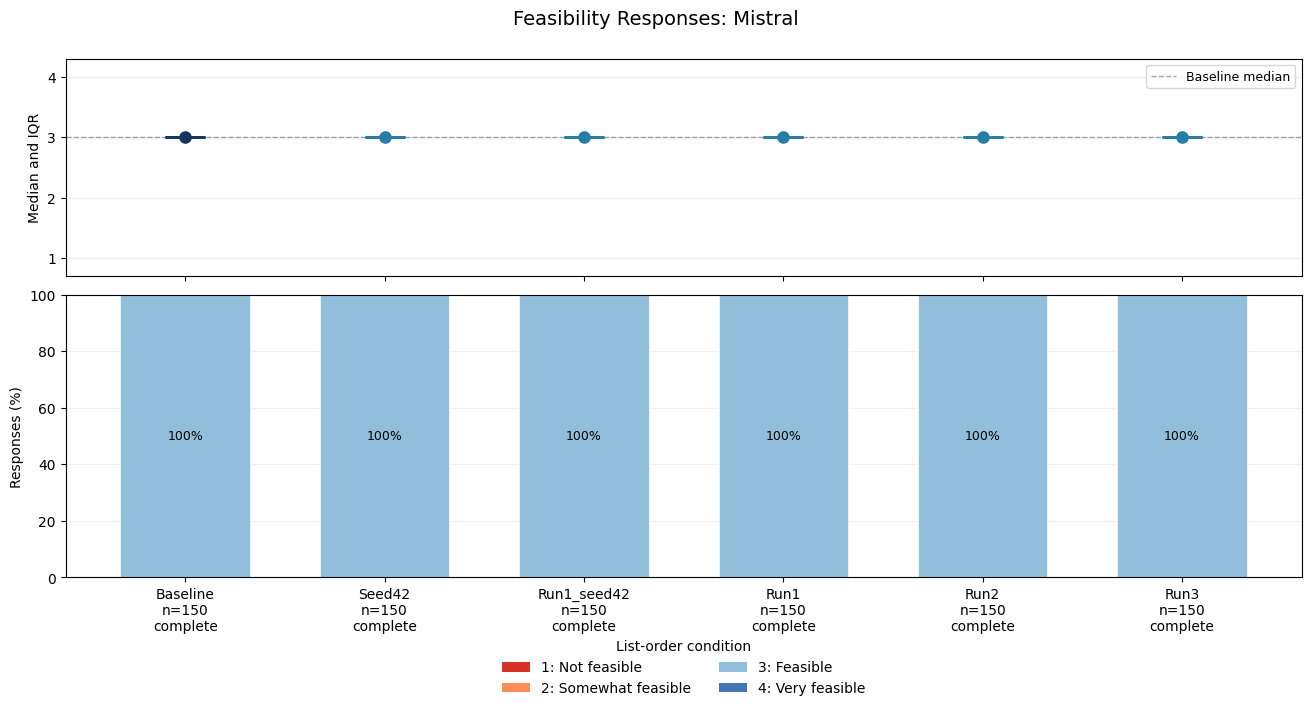

In [9]:
# Cell 4 — one figure per base model
for model in MODELS:
    model_data = data[data["base_model"] == model]

    if model_data.empty:
        print(f"{model}: no data available for plotting.")
        continue

    stats = (
        summary[summary["base_model"] == model]
        .set_index("condition")
        .reindex(CONDITIONS)
    )

    x = np.arange(len(CONDITIONS))
    available = stats["n"].to_numpy() > 0

    fig, (ax_summary, ax_distribution) = plt.subplots(
        2, 1,
        figsize=(13, 7),
        sharex=True,
        gridspec_kw={"height_ratios": [1, 1.3]},
        constrained_layout=True,
    )

    fig.suptitle(
        f"Feasibility Responses: {MODEL_DISPLAY_NAMES[model]}\n",
        fontsize=14,
    )

    # Baseline median reference, when available.
    baseline_median = stats.loc["Baseline", "median"]

    if pd.notna(baseline_median):
        ax_summary.axhline(
            baseline_median,
            color="grey",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
            label="Baseline median",
        )

    # Draw intervals directly: this also handles zero-width IQRs.
    for position, condition in enumerate(CONDITIONS):
        row = stats.loc[condition]

        if row["n"] == 0:
            continue

        color = "#17365d" if condition == "Baseline" else "#277da8"

        ax_summary.vlines(
            position, row["q1"], row["q3"],
            color=color, linewidth=3,
        )
        ax_summary.hlines(
            [row["q1"], row["q3"]],
            position - 0.10, position + 0.10,
            color=color, linewidth=2,
        )
        ax_summary.scatter(
            position, row["median"],
            color=color, s=65, zorder=3,
        )

    ax_summary.set_ylabel("Median and IQR")
    ax_summary.set_ylim(0.7, 4.3)
    ax_summary.set_yticks([1, 2, 3, 4])
    ax_summary.grid(axis="y", alpha=0.25)

    if pd.notna(baseline_median):
        ax_summary.legend(loc="best", fontsize=9)

    # Rating distributions, calculated separately for each condition.
    percentages = pd.DataFrame(
        np.nan,
        index=CONDITIONS,
        columns=[1, 2, 3, 4],
    )

    for condition in CONDITIONS:
        ratings = model_data.loc[
            model_data["condition"] == condition, "rating"
        ]

        if not ratings.empty:
            percentages.loc[condition] = (
                ratings.value_counts(normalize=True)
                .reindex([1, 2, 3, 4], fill_value=0)
                .mul(100)
            )

    bottom = np.zeros(len(CONDITIONS))

    for rating in [1, 2, 3, 4]:
        heights = percentages[rating].to_numpy(dtype=float)

        ax_distribution.bar(
            x[available],
            heights[available],
            bottom=bottom[available],
            color=COLORS[rating],
            width=0.65,
            edgecolor="white",
            linewidth=0.5,
        )

        for position in x[available]:
            height = heights[position]

            if height >= 8:
                ax_distribution.text(
                    position,
                    bottom[position] + height / 2,
                    f"{height:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color="white" if rating in [1, 4] else "black",
                )

        bottom += np.nan_to_num(heights)

    tick_labels = []

    for condition in CONDITIONS:
        row = stats.loc[condition]
        status = (
            "missing" if row["n"] == 0
            else "complete" if row["status"] == "Complete"
            else "partial"
        )

        tick_labels.append(
            f"{condition}\nn={int(row['n'])}\n{status}"
        )

    ax_distribution.set_xticks(x)
    ax_distribution.set_xticklabels(tick_labels)
    ax_distribution.set_xlim(-0.6, len(CONDITIONS) - 0.4)
    ax_distribution.set_ylim(0, 100)
    ax_distribution.set_ylabel("Responses (%)")
    ax_distribution.set_xlabel("List-order condition")
    ax_distribution.set_axisbelow(True)
    ax_distribution.grid(axis="y", alpha=0.2)

    ax_distribution.legend(
        handles=[
            Patch(
                facecolor=COLORS[rating],
                label=f"{rating}: {LABELS[rating]}",
            )
            for rating in [1, 2, 3, 4]
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, -0.25),
        ncol=2,
        frameon=False,
    )

    for extension in ("png", "eps"):
        output_path = ROOT / f"feasibility-responses_{model}.{extension}"

        fig.savefig(
            output_path,
            format=extension,
            dpi=300,
            bbox_inches="tight",
        )
        print(f"Saved: {output_path}")

    plt.show()